# 04c · Classificação ABC/XYZ dos SKUs
- **ABC** (importância): pela receita (unidades **pedidas** × preço) nos 24 meses.
  A = SKUs que somam até 80% da receita; B = de 80% a 95%; C = o restante.
  Usamos unidades *pedidas* (demanda real) e não *separadas*, porque a ruptura esconderia
  a importância dos itens que mais faltam.
- **XYZ** (previsibilidade): pelo coeficiente de variação (CV = desvio / média) da demanda
  **semanal**. X: CV < 0,5 (estável) · Y: 0,5–1,0 · Z: > 1,0 (errática).

A matriz ABC × XYZ orienta política de estoque (nível de serviço), frequência de contagem
cíclica e slotting (Fase 5).

*EN summary: ABC by revenue (ordered units × price) and XYZ by weekly demand CV; output
`sku_abc_xyz.csv` feeds safety stock (04d), cycle counting and slotting.*

In [1]:
import sys
sys.path.insert(0, "../src")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dcanalysis import q, save, savefig, log

NB = "04c"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Demanda semanal por SKU (semanas completas do período; warm-up excluído)
dem = q("""SELECT sku_id, order_date, SUM(qty_ordered_units) AS und
           FROM fact_order_line WHERE order_date >= '2024-11-01'
           GROUP BY sku_id, order_date""")
dem["semana"] = pd.to_datetime(dem.order_date).dt.to_period("W-SUN")
semanal = dem.pivot_table(index="semana", columns="sku_id", values="und", aggfunc="sum").fillna(0)
semanal = semanal.iloc[1:-1]   # tira a 1ª e a última semana (incompletas)
sku = q("SELECT sku_id, sku_code, zone, category, status, unit_price, unit_cost FROM dim_sku")
print(f"{semanal.shape[0]} semanas x {semanal.shape[1]} SKUs com demanda "
      f"(cadastro tem {len(sku)} SKUs)")

103 semanas x 599 SKUs com demanda (cadastro tem 600 SKUs)


In [3]:
# --- ABC pela receita ---
total = semanal.sum().rename("und_pedidas").reset_index()
abc = sku.merge(total, on="sku_id", how="left").fillna({"und_pedidas": 0})
abc["receita"] = abc.und_pedidas * abc.unit_price
abc = abc.sort_values("receita", ascending=False)
abc["receita_acum_pct"] = 100 * abc.receita.cumsum() / abc.receita.sum()
# Regra: o SKU entra na classe da faixa onde a receita ACUMULADA ANTERIOR a ele está
anterior = abc.receita_acum_pct.shift(fill_value=0)
abc["abc"] = np.select([anterior < 80, anterior < 95], ["A", "B"], "C")

# --- XYZ pelo CV semanal ---
media = semanal.mean(); desvio = semanal.std()
cv = (desvio / media).rename("cv_semanal").reset_index()
abc = abc.merge(cv, on="sku_id", how="left")
abc["xyz"] = np.select([abc.cv_semanal < 0.5, abc.cv_semanal <= 1.0], ["X", "Y"], "Z")
abc.loc[abc.und_pedidas == 0, ["abc", "xyz"]] = ["C", "Z"]   # sem demanda: pior classe (sinalizado abaixo)
abc["classe"] = abc.abc + abc.xyz

print("SKUs sem nenhuma demanda no período:", (abc.und_pedidas == 0).sum())
resumo = abc.groupby("abc").agg(skus=("sku_id", "size"), receita_pct=("receita", "sum"))
resumo["skus_pct"] = (100 * resumo.skus / resumo.skus.sum()).round(1)
resumo["receita_pct"] = (100 * resumo.receita_pct / abc.receita.sum()).round(1)
resumo

SKUs sem nenhuma demanda no período: 1


,skus,receita_pct,skus_pct
abc,,,
A,122,80.1,20.3
B,163,14.9,27.2
C,315,5.0,52.5


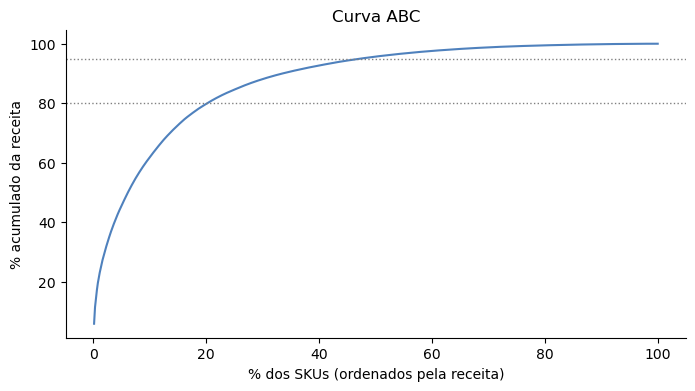

In [4]:
# Curva de Pareto: o gráfico clássico do ABC (acumulado × % de SKUs).
fig, ax = plt.subplots(figsize=(8, 4))
x = 100 * np.arange(1, len(abc) + 1) / len(abc)
ax.plot(x, abc.receita_acum_pct, color="#4F81BD")
for lim in (80, 95):
    ax.axhline(lim, color="grey", ls=":", lw=1)
ax.set_xlabel("% dos SKUs (ordenados pela receita)"); ax.set_ylabel("% acumulado da receita")
ax.set_title("Curva ABC")
savefig(fig, "04c_curva_abc")

In [5]:
# Matriz ABC × XYZ (contagem de SKUs e % da receita)
matriz_n = pd.crosstab(abc.abc, abc.xyz)
matriz_r = (pd.crosstab(abc.abc, abc.xyz, values=abc.receita, aggfunc="sum")
            .div(abc.receita.sum()).mul(100).round(1))
print("Número de SKUs:\n", matriz_n, "\n\n% da receita:\n", matriz_r)

Número de SKUs:
 xyz    X    Y   Z
abc              
A    122    0   0
B    152   10   1
C    128  153  34 

% da receita:
 xyz     X    Y    Z
abc                
A    80.1  NaN  NaN
B    14.1  0.7  0.1
C     3.0  1.8  0.2


In [6]:
# Distribuição por zona: o frio tem itens A? (importa para slotting e para a política de frio)
pd.crosstab(abc.zone, abc.abc, margins=True)

abc,A,B,C,All
zone,,,,
chilled,37,29,24,90
dry,65,113,272,450
frozen,20,21,19,60
All,122,163,315,600


**Leitura:** 20% dos SKUs (122) fazem 80% da receita — Pareto clássico. Todos os A são **X**
(demanda semanal estável), o que é ótimo: os itens que mais importam são previsíveis, então ruptura
neles vem da política de estoque, já que a demanda é fácil de prever. A variabilidade se concentra na cauda C
(187 SKUs CY/CZ). O frio tem proporcionalmente mais itens A (41% do resfriado) que o seco (14%).
Um SKU não teve nenhuma demanda nos 24 meses (classificado CZ e sinalizado).

## Política sugerida por quadrante
| Quadrante | Característica | Nível de serviço alvo | Revisão | Contagem cíclica |
|---|---|---|---|---|
| AX, AY | muito importante, previsível | 98% | semanal | mensal |
| AZ | muito importante, errático | 98% + atenção a promoções | semanal | mensal |
| BX, BY, BZ | importância média | 95% | quinzenal | trimestral |
| CX, CY | pouca receita | 90% | mensal | semestral |
| CZ | pouca receita e errático | 90% ou sob encomenda; candidato a descontinuar | mensal | semestral |

Esses níveis de serviço alimentam o estoque de segurança da 04d.

In [7]:
saida = abc[["sku_id", "sku_code", "zone", "category", "status", "und_pedidas", "receita",
             "receita_acum_pct", "abc", "cv_semanal", "xyz", "classe"]].round(3)
save(saida, "sku_abc_xyz")
log(NB, f"ABC/XYZ de {len(saida)} SKUs (receita = und pedidas x preço; CV semanal, "
        f"{semanal.shape[0]} semanas completas) -> sku_abc_xyz.csv")
saida.head(10)

,sku_id,sku_code,zone,category,status,und_pedidas,receita,receita_acum_pct,abc,cv_semanal,xyz,classe
0,446,SKU000447,dry,Biscoitos e Doces,ACTIVE,4158776.0,34185138.72,5.899,A,0.249,X,AX
1,525,SKU000526,chilled,Frios e Embutidos,ACTIVE,757425.0,32266305.00,11.466,A,0.165,X,AX
2,517,SKU000518,chilled,Frios e Embutidos,ACTIVE,464940.0,17137688.40,14.423,A,0.161,X,AX
3,383,SKU000384,dry,Biscoitos e Doces,ACTIVE,4153955.0,16325043.15,17.240,A,0.250,X,AX
4,369,SKU000370,dry,Biscoitos e Doces,ACTIVE,1181065.0,13487762.30,19.567,A,0.308,X,AX
5,503,SKU000504,chilled,Laticínios,ACTIVE,944479.0,10200373.20,21.327,A,0.202,X,AX
6,489,SKU000490,chilled,Laticínios,ACTIVE,1859150.0,10113776.00,23.073,A,0.181,X,AX
7,597,SKU000598,frozen,Carnes e Aves,ACTIVE,193572.0,8521039.44,24.543,A,0.270,X,AX
8,52,SKU000053,dry,Mercearia,ACTIVE,448011.0,8431567.02,25.998,A,0.305,X,AX
9,590,SKU000591,frozen,Sorvetes,ACTIVE,189480.0,7800891.60,27.344,A,0.250,X,AX
